In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import train_test_split

# 한글 폰트 설정 (Colab 환경에서 깨짐 방지)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 1. 데이터 불러오기 (한글 인코딩 cp949 적용)
try:
    forecast_df = pd.read_csv('/content/forecast.csv', encoding='cp949')
except UnicodeDecodeError:
    forecast_df = pd.read_csv('/content/forecast.csv', encoding='utf-8')

try:
    auction_df = pd.read_csv('/content/정가수의only.csv', encoding='cp949')
except UnicodeDecodeError:
    auction_df = pd.read_csv('/content/정가수의only.csv', encoding='utf-8')

print("Forecast Data Preview:")
display(forecast_df.head(2))
print("\nAuction Data Preview:")
display(auction_df.head(2))

Forecast Data Preview:


,지점,지점명,일시,평균기온(°C),강수 계속시간(hr),10분 최다 강수량(mm),합계 일조시간(hr),일 최심신적설(cm)
0,184,제주,2018-01-01,6.4,NaN,NaN,2.7,NaN
1,184,제주,2018-01-02,7.0,NaN,NaN,8.2,NaN



Auction Data Preview:


,avgprc,gds_mclsf_nm,gds_sclsf_cd,gds_sclsf_nm,grd_nm,hgprc,lwprc,pkg_nm,sz_nm,totprc,trd_clcln_ymd,trd_se,unit_qty,query_whsl_mrkt_nm,unit_qty_grp,gds_sclsf_grp
0,7768.421,감귤,1,조생귤,특,9200.0,4600.0,상자,.,6497700.0,2021-01-04,정가수의,5.0,부산반여,중형(3.5kg초과~7.5kg이하),노지온주
1,6928.571,감귤,1,조생귤,특,8400.0,4500.0,상자,.,1611200.0,2021-01-04,정가수의,5.0,부산반여,중형(3.5kg초과~7.5kg이하),노지온주


### LightGBM을 이용한 새로운 거래량과 가격의 관계 분석
거래량이 아주 적을 때 오히려 가격 분산이 매우 넓고, 일정한 거래량(약 500 이상) 수준을 넘어가면 오히려 가격이 특정 범위 내로 안정화(수렴) / 상당수의 데이터가 특정 거래량 구간에 밀집



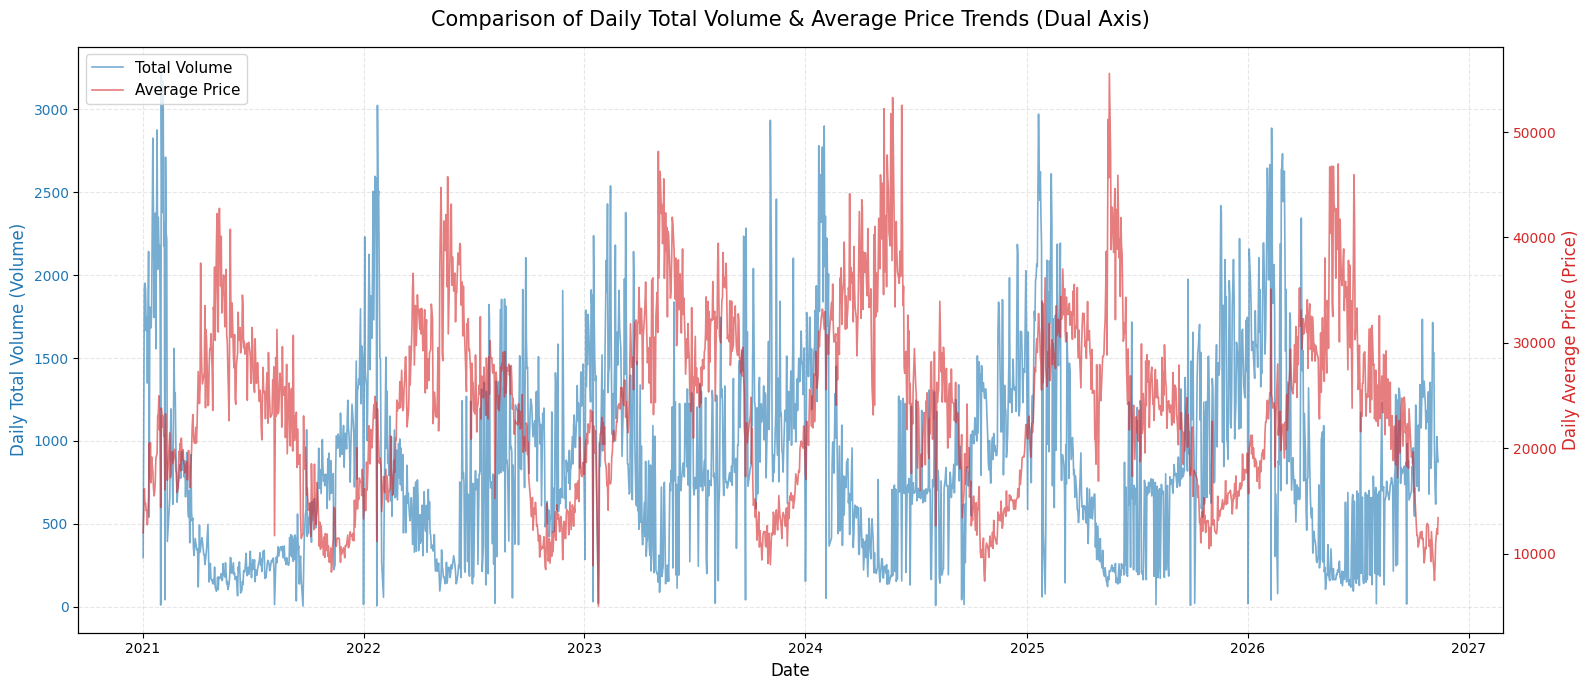

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 메모리에 이미 로드된 auction_df 등을 기반으로 안전하게 초기화.
if 'daily_data' not in globals() and 'auction_df' in globals():
    # calculated_vol 컬럼 확보
    if 'calculated_vol' not in auction_df.columns:
        vol_cols = [col for col in auction_df.columns if 'vol' in col or 'qty' in col or '수량' in col]
        auction_df['calculated_vol'] = auction_df[vol_cols[0]] if vol_cols else auction_df['unit_qty']

    daily_data = auction_df.rename(columns={
        'trd_clcln_ymd': 'trd_clcln_ymd',
        'calculated_vol': '거래량',
        'avgprc': '가격'
    })[['trd_clcln_ymd', '거래량', '가격']].copy()

# 1. 날짜별 총 거래량(합계) 및 평균 가격 계산
daily_summary = daily_data.groupby('trd_clcln_ymd').agg(
    총거래량=('거래량', 'sum'),
    평균가격=('가격', 'mean')
).reset_index()

# 결측치 제거
daily_summary = daily_summary.dropna()

# 폰트 깨짐 및 경고를 우회하기 위해 한글 대신 범용 영문 레이블 사용 및 한글 폰트 기본값 우회 설정
plt.rcParams['axes.unicode_minus'] = False

# 날짜 정렬
daily_summary['trd_clcln_ymd'] = pd.to_datetime(daily_summary['trd_clcln_ymd'])
daily_summary_sorted = daily_summary.sort_values('trd_clcln_ymd').reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(16, 7))

# 1. 왼쪽 Y축: 일별 총 거래량 (파란색)
color = '#1f77b4'
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Daily Total Volume (Volume)', color=color, fontsize=12)
line1 = ax1.plot(daily_summary_sorted['trd_clcln_ymd'], daily_summary_sorted['총거래량'], color=color, alpha=0.6, linewidth=1.2, label='Total Volume')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.3)

# 2. 오른쪽 보조 Y축: 일별 평균 가격 (빨간색)
ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Daily Average Price (Price)', color=color, fontsize=12)
line2 = ax2.plot(daily_summary_sorted['trd_clcln_ymd'], daily_summary_sorted['평균가격'], color=color, alpha=0.6, linewidth=1.2, label='Average Price')
ax2.tick_params(axis='y', labelcolor=color)

# 범례 합치기
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=11)

plt.title('Comparison of Daily Total Volume & Average Price Trends (Dual Axis)', fontsize=15, pad=15)
fig.tight_layout()
plt.show()

###전체 거래량 추정

In [33]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. 기상 데이터 날짜 형식 변환 및 요약
forecast_df['일시'] = pd.to_datetime(forecast_df['일시'])
# 기상 변수 중 필요한 피처 선택 (평균기온, 강수량 등)
weather_daily = forecast_df.groupby('일시').agg({
    '평균기온(°C)': 'mean',
    '강수 계속시간(hr)': 'mean',
    '10분 최다 강수량(mm)': 'mean'
}).reset_index().rename(columns={'일시': 'trd_clcln_ymd'})

# 2. 거래량 데이터와 기상 데이터 병합
# 전체 날짜 범위를 생성하여 휴일(데이터가 없는 날)을 명시적으로 빈 날짜로 생성
all_dates = pd.date_range(start=daily_summary_sorted['trd_clcln_ymd'].min(),
                          end=daily_summary_sorted['trd_clcln_ymd'].max(), freq='D')
date_df = pd.DataFrame({'trd_clcln_ymd': all_dates})

merged_df = pd.merge(date_df, daily_summary_sorted, on='trd_clcln_ymd', how='left')
merged_df = pd.merge(merged_df, weather_daily, on='trd_clcln_ymd', how='left')

# 도매시장 휴일 반영: 거래량 데이터가 결측치(NaN)인 날은 휴일이므로 거래량을 0으로 처리
merged_df['is_holiday'] = merged_df['총거래량'].isna().astype(int)
merged_df['총거래량'] = merged_df['총거래량'].fillna(0)
merged_df['평균가격'] = merged_df['평균가격'].fillna(0)

# 결측 기상 데이터는 직전 값으로 채움 (Forward fill)
merged_df = merged_df.ffill().bfill()

# 3. 시계열 피처 생성
merged_df['year'] = merged_df['trd_clcln_ymd'].dt.year
merged_df['month'] = merged_df['trd_clcln_ymd'].dt.month
merged_df['day'] = merged_df['trd_clcln_ymd'].dt.day
merged_df['dayofweek'] = merged_df['trd_clcln_ymd'].dt.dayofweek

# Lag 피처 생성 (1일 전, 7일 전 거래량)
merged_df['volume_lag_1'] = merged_df['총거래량'].shift(1)
merged_df['volume_lag_7'] = merged_df['총거래량'].shift(7)
merged_df = merged_df.dropna().reset_index(drop=True)

print("예측 모델용 최종 데이터 셋:")
display(merged_df.head(5))

예측 모델용 최종 데이터 셋:


,trd_clcln_ymd,총거래량,평균가격,평균기온(°C),강수 계속시간(hr),10분 최다 강수량(mm),is_holiday,year,month,day,dayofweek,volume_lag_1,volume_lag_7
0,2021-01-09,1349.0,12728.889828,0.375,20.095,1.325,0,2021,1,9,5,1747.0,296.0
1,2021-01-10,0.0,0.000000,2.825,5.190,1.325,1,2021,1,10,6,1349.0,0.0
2,2021-01-11,2142.3,15391.581476,3.500,7.960,1.325,0,2021,1,11,0,0.0,1925.0
3,2021-01-12,540.5,20480.441151,4.300,3.015,1.325,0,2021,1,12,1,2142.3,1951.6
4,2021-01-13,1808.0,17210.529076,9.775,3.015,1.325,0,2021,1,13,2,540.5,1914.5


In [34]:
# 4. Train / Test Split (시계열 특성을 고려하여 순차 분할)
features = ['평균기온(°C)', '강수 계속시간(hr)', '10분 최다 강수량(mm)',
            'is_holiday', 'year', 'month', 'day', 'dayofweek', 'volume_lag_1', 'volume_lag_7']
target = '총거래량'

split_idx = int(len(merged_df) * 0.8)
train_df = merged_df.iloc[:split_idx]
test_df = merged_df.iloc[split_idx:]

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

# 5. LightGBM 모델 정의 및 학습
model = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, random_state=42, verbose=-1)
model.fit(X_train, y_train)

# 6. 예측 및 성능 평가
test_df = test_df.copy()
test_df['predicted_volume'] = model.predict(X_test)

# 휴일인 날(is_holiday == 1)은 시장이 열리지 않으므로 예측값을 강제로 0으로 보정
test_df.loc[test_df['is_holiday'] == 1, 'predicted_volume'] = 0

rmse = np.sqrt(mean_squared_error(test_df[target], test_df['predicted_volume']))
r2 = r2_score(test_df[target], test_df['predicted_volume'])

print(f"모델 평가 결과 (Test Set):")
print(f"RMSE (오차 표준편차): {rmse:.2f}")
print(f"R² (결정계수 - 설명력): {r2:.4f}")

모델 평가 결과 (Test Set):
RMSE (오차 표준편차): 390.56
R² (결정계수 - 설명력): 0.6690


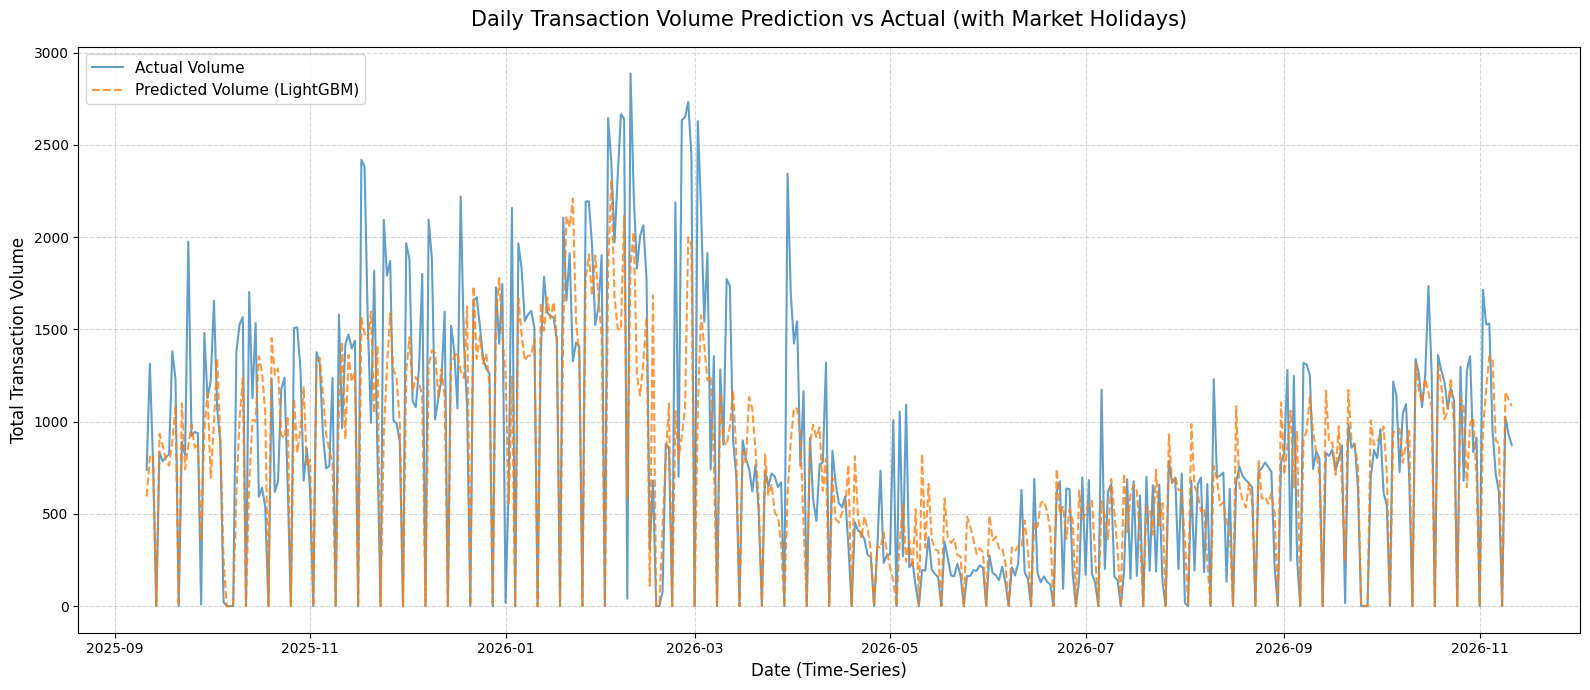

In [35]:
# 7. 실제 거래량 vs 예측 거래량 시각화 (한글 폰트 부재 경고 방지를 위해 기본 폰트 사용 및 영문 표기)
import matplotlib.pyplot as plt

# 폰트 에러 방지를 위해 기본 폰트 설정 복원
plt.rc('font', family='sans-serif')
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(16, 7))
plt.plot(test_df['trd_clcln_ymd'], test_df[target], label='Actual Volume', color='#1f77b4', alpha=0.7)
plt.plot(test_df['trd_clcln_ymd'], test_df['predicted_volume'], label='Predicted Volume (LightGBM)', color='#ff7f0e', alpha=0.8, linestyle='--')

plt.title('Daily Transaction Volume Prediction vs Actual (with Market Holidays)', fontsize=15, pad=15)
plt.xlabel('Date (Time-Series)', fontsize=12)
plt.ylabel('Total Transaction Volume', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 감귤별 거래량 및 가격 예측

[만감류 거래량 예측 결과]
RMSE: 259.27
R² (결정계수): 0.6950



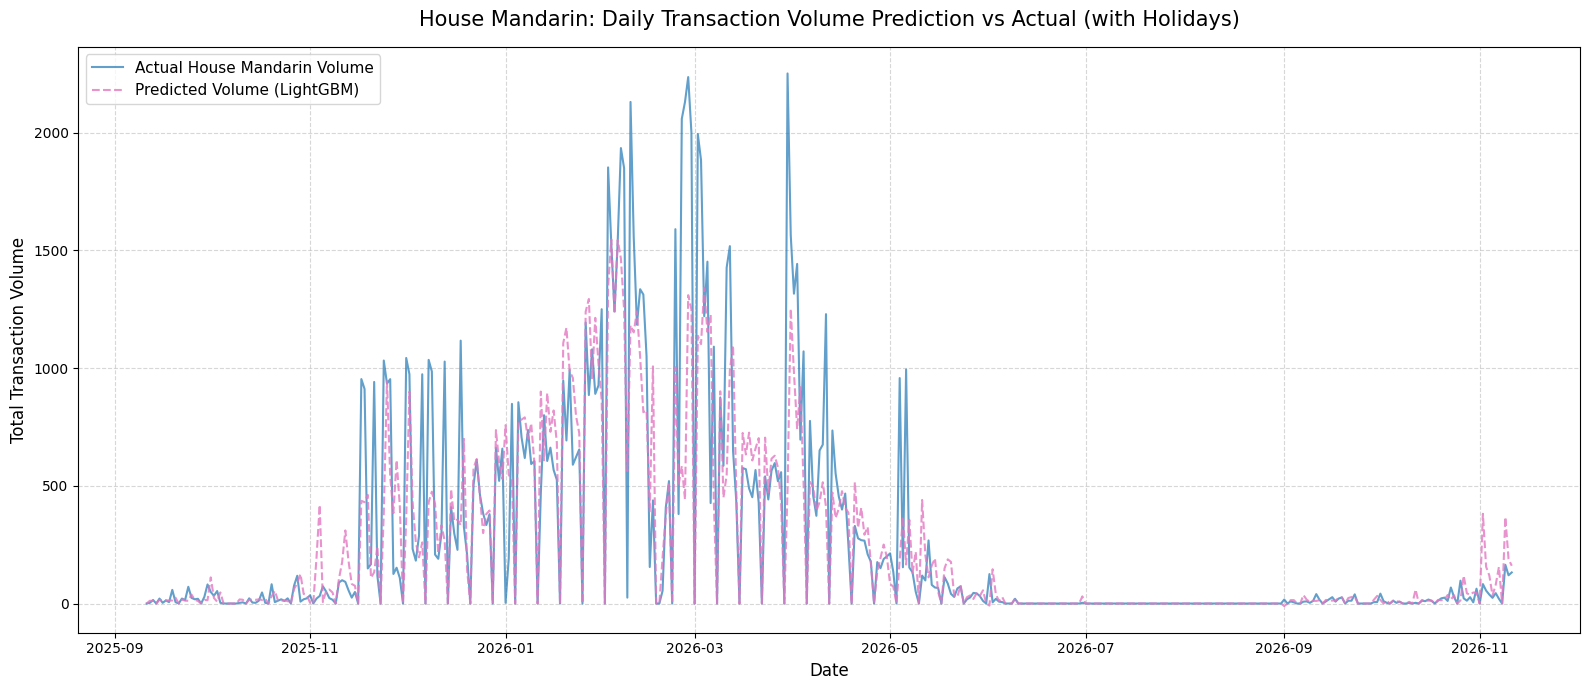

In [36]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. 감귤 데이터 필터링
house_citrus = auction_df[auction_df['gds_sclsf_grp'] == '만감류'].copy()
house_citrus['trd_clcln_ymd'] = pd.to_datetime(house_citrus['trd_clcln_ymd'])

# 거래량 컬럼 정합성 확보 (calculated_vol이 없으면 unit_qty 등을 활용하여 정의)
if 'calculated_vol' not in house_citrus.columns:
    # 'del_vol' 이나 다른 거래량 표현 컬럼이 있는지 확인 후 없으면 1로 임시 지정 및 가중치 곱 계산
    vol_cols = [col for col in house_citrus.columns if 'vol' in col or 'qty' in col or 'del' in col or '수량' in col]
    if vol_cols:
        # 가장 적합한 첫 번째 컬럼을 거래량으로 사용
        house_citrus['calculated_vol'] = house_citrus[vol_cols[0]]
    else:
        # 기본 백업 처리
        house_citrus['calculated_vol'] = house_citrus['unit_qty']

# 2. 날짜별 총 거래량 및 평균 가격 집계
daily_house = house_citrus.groupby('trd_clcln_ymd').agg(
    총거래량=('calculated_vol', 'sum'),
    평균가격=('avgprc', 'mean')
).reset_index()

# 3. 전체 날짜 그리드를 생성하여 휴일(도매시장 비영업일) 반영
min_date = daily_house['trd_clcln_ymd'].min()
max_date = daily_house['trd_clcln_ymd'].max()
all_dates = pd.date_range(start=min_date, end=max_date, freq='D')
date_grid = pd.DataFrame({'trd_clcln_ymd': all_dates})

merged_house = pd.merge(date_grid, daily_house, on='trd_clcln_ymd', how='left')

# 4. 기상 데이터 연계
forecast_df['일시'] = pd.to_datetime(forecast_df['일시'])
weather_daily_house = forecast_df.groupby('일시').agg({
    '평균기온(°C)': 'mean',
    '강수 계속시간(hr)': 'mean',
    '10분 최다 강수량(mm)': 'mean'
}).reset_index().rename(columns={'일시': 'trd_clcln_ymd'})

merged_house = pd.merge(merged_house, weather_daily_house, on='trd_clcln_ymd', how='left')

# 휴일 정의: 원본 거래량 데이터가 없는 날
merged_house['is_holiday'] = merged_house['총거래량'].isna().astype(int)
merged_house['총거래량'] = merged_house['총거래량'].fillna(0)
merged_house['평균가격'] = merged_house['평균가격'].fillna(0)

# 결측 기상 정보 및 가격 직전 값 처리 (Forward fill)
merged_house = merged_house.ffill().bfill()

# 5. 시계열 파생 변수 및 Lag 피처 생성
merged_house['year'] = merged_house['trd_clcln_ymd'].dt.year
merged_house['month'] = merged_house['trd_clcln_ymd'].dt.month
merged_house['day'] = merged_house['trd_clcln_ymd'].dt.day
merged_house['dayofweek'] = merged_house['trd_clcln_ymd'].dt.dayofweek

merged_house['volume_lag_1'] = merged_house['총거래량'].shift(1)
merged_house['volume_lag_7'] = merged_house['총거래량'].shift(7)
merged_house = merged_house.dropna().reset_index(drop=True)

# 6. Train / Test Split (시계열 순차 분할)
features = ['평균기온(°C)', '강수 계속시간(hr)', '10분 최다 강수량(mm)',
            'is_holiday', 'year', 'month', 'day', 'dayofweek', 'volume_lag_1', 'volume_lag_7']
target = '총거래량'

split_idx = int(len(merged_house) * 0.8)
train_df = merged_house.iloc[:split_idx]
test_df = merged_house.iloc[split_idx:].copy()

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

# 7. LightGBM 모델 학습
model_house = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, random_state=42, verbose=-1)
model_house.fit(X_train, y_train)

# 예측 및 휴일 보정
test_df['predicted_volume'] = model_house.predict(X_test)
test_df.loc[test_df['is_holiday'] == 1, 'predicted_volume'] = 0

rmse = np.sqrt(mean_squared_error(test_df[target], test_df['predicted_volume']))
r2 = r2_score(test_df[target], test_df['predicted_volume'])

print(f"[만감류 거래량 예측 결과]")
print(f"RMSE: {rmse:.2f}")
print(f"R² (결정계수): {r2:.4f}\n")

# 8. 시각화
plt.figure(figsize=(16, 7))
plt.plot(test_df['trd_clcln_ymd'], test_df[target], label='Actual House Mandarin Volume', color='#1f77b4', alpha=0.7)
plt.plot(test_df['trd_clcln_ymd'], test_df['predicted_volume'], label='Predicted Volume (LightGBM)', color='#e377c2', alpha=0.8, linestyle='--')

plt.title('House Mandarin: Daily Transaction Volume Prediction vs Actual (with Holidays)', fontsize=15, pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Transaction Volume', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 감귤 단독 가격 예측 (LightGBM)
앞선 거래량 예측 정합성 프레임워크를 기반으로, 휴일(비영업일) 공백 보정과 시계열 Lag 피처를 반영하여 하우스감귤의 일별 평균 가격을 예측하는 모델을 실행합니다.

In [37]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. 감귤 & 등급 '특' 필터링
target_citrus = auction_df[
    (auction_df['gds_sclsf_grp'] == '만감류') &
    (auction_df['grd_nm'] == '특')
].copy()
target_citrus['trd_clcln_ymd'] = pd.to_datetime(target_citrus['trd_clcln_ymd'])

# 거래량 컬럼 정합성 처리
if 'calculated_vol' not in target_citrus.columns:
    vol_cols = [col for col in target_citrus.columns if 'vol' in col or 'qty' in col or 'del' in col or '수량' in col]
    target_citrus['calculated_vol'] = target_citrus[vol_cols[0]] if vol_cols else target_citrus['unit_qty']

# 기상 데이터 전처리
forecast_df['일시'] = pd.to_datetime(forecast_df['일시'])
weather_daily_df = forecast_df.groupby('일시').agg({
    '평균기온(°C)': 'mean',
    '강수 계속시간(hr)': 'mean',
    '10분 최다 강수량(mm)': 'mean'
}).reset_index().rename(columns={'일시': 'trd_clcln_ymd'})

# 고유한 unit_qty_grp 그룹 추출 (결측값 제외)
unique_grps = [grp for grp in target_citrus['unit_qty_grp'].dropna().unique()]


In [38]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, r2_score

# 1. 원본 데이터의 시장명 컬럼 정의
mkt_col = 'query_whsl_mrkt_nm' if 'query_whsl_mrkt_nm' in target_citrus.columns else 'whsl_mrkt_nm'

# 2. 시장별 고유 영업 캘린더 생성
print("시장별 고유 영업 캘린더 생성 중...")
market_calendars = []
unique_markets = target_citrus[mkt_col].dropna().unique()

for mkt in unique_markets:
    mkt_dates = target_citrus[target_citrus[mkt_col] == mkt]['trd_clcln_ymd'].dropna().unique()
    mkt_min = mkt_dates.min()
    mkt_max = mkt_dates.max()

    all_days = pd.date_range(start=mkt_min, end=mkt_max, freq='D')
    mkt_grid = pd.DataFrame({
        'trd_clcln_ymd': all_days,
        mkt_col: mkt
    })
    market_calendars.append(mkt_grid)

market_calendar_df = pd.concat(market_calendars, ignore_index=True)
target_citrus['trd_clcln_ymd'] = pd.to_datetime(target_citrus['trd_clcln_ymd'])

# 3. 만감류가 통합된 대체재(Substitute) 4대 대분류 일별 평균가격 매핑 구축
print("대체재(노지온주, 하우스감귤, 비가림감귤, 만감류) 일별 평균가격 테이블 생성 중...")
sub_categories = ['노지온주', '하우스감귤', '비가림감귤', '만감류']
sub_prices_list = []

for cat in sub_categories:
    cat_df_sub = auction_df[auction_df['gds_sclsf_grp'] == cat].copy()
    cat_df_sub['trd_clcln_ymd'] = pd.to_datetime(cat_df_sub['trd_clcln_ymd'])
    daily_avg = cat_df_sub.groupby('trd_clcln_ymd')['avgprc'].mean().reset_index().rename(
        columns={'avgprc': f'price_sub_{cat}'}
    )
    sub_prices_list.append(daily_avg)

# 통합 날짜 백본 프레임
min_date_all = auction_df['trd_clcln_ymd'].min()
max_date_all = auction_df['trd_clcln_ymd'].max()
date_grid_all = pd.DataFrame({'trd_clcln_ymd': pd.date_range(start=min_date_all, end=max_date_all, freq='D')})

sub_matrix_clean = date_grid_all.copy()
for sub_df in sub_prices_list:
    sub_matrix_clean = pd.merge(sub_matrix_clean, sub_df, on='trd_clcln_ymd', how='left')

# 결측치는 직전 영업일 유지 및 다음 영업일 보정
sub_matrix_clean = sub_matrix_clean.ffill().bfill()

# Lag 피처 생성 (1일 전 시점 기준의 대체재 가격 정보 구축)
for cat in sub_categories:
    sub_matrix_clean[f'price_sub_{cat}_lag_1'] = sub_matrix_clean[f'price_sub_{cat}'].shift(1)

sub_matrix_clean = sub_matrix_clean.ffill().bfill()
sub_matrix_clean['trd_clcln_ymd'] = pd.to_datetime(sub_matrix_clean['trd_clcln_ymd'])

# 4. 그룹별 예측을 4대 대체재 대분류 변수를 적용하여 순차 학습
group_results_by_market_calendar = {}
sub_features_lag1 = [f'price_sub_{cat}_lag_1' for cat in sub_categories]

for grp in unique_grps:
    print(f"\n{'='*65}\n[그룹: {grp}] 시장별 캘린더 및 통합 만감류/비가림 대체재 기반 순차 파이프라인\n{'='*65}")

    grp_df = target_citrus[target_citrus['unit_qty_grp'] == grp].copy()
    if len(grp_df) < 100:
        print(f"-> 데이터 수가 너무 적어 ({len(grp_df)}개) 예측을 건너뜁니다.")
        continue

    daily_mkt_grp = grp_df.groupby(['trd_clcln_ymd', mkt_col]).agg({
        'calculated_vol': 'sum',
        'avgprc': 'mean'
    }).reset_index().rename(columns={'calculated_vol': '총거래량', 'avgprc': '평균가격'})

    merged_mkt = pd.merge(market_calendar_df, daily_mkt_grp, on=['trd_clcln_ymd', mkt_col], how='left')
    merged_mkt = pd.merge(merged_mkt, weather_daily_df, on='trd_clcln_ymd', how='left')
    merged_mkt = pd.merge(merged_mkt, sub_matrix_clean[['trd_clcln_ymd'] + sub_features_lag1], on='trd_clcln_ymd', how='left')

    merged_mkt['is_holiday'] = merged_mkt['평균가격'].isna().astype(int)
    merged_mkt['총거래량'] = merged_mkt['총거래량'].fillna(0)

    merged_mkt['평균가격'] = merged_mkt.groupby(mkt_col)['평균가격'].ffill().bfill()
    merged_mkt = merged_mkt.ffill().bfill()

    merged_mkt['year'] = merged_mkt['trd_clcln_ymd'].dt.year
    merged_mkt['month'] = merged_mkt['trd_clcln_ymd'].dt.month
    merged_mkt['day'] = merged_mkt['trd_clcln_ymd'].dt.day
    merged_mkt['dayofweek'] = merged_mkt['trd_clcln_ymd'].dt.dayofweek

    merged_mkt['volume_lag_1'] = merged_mkt.groupby(mkt_col)['총거래량'].shift(1)
    merged_mkt['volume_lag_7'] = merged_mkt.groupby(mkt_col)['총거래량'].shift(7)
    merged_mkt['price_lag_1'] = merged_mkt.groupby(mkt_col)['평균가격'].shift(1)
    merged_mkt['price_lag_2'] = merged_mkt.groupby(mkt_col)['평균가격'].shift(2)
    merged_mkt['price_lag_7'] = merged_mkt.groupby(mkt_col)['평균가격'].shift(7)

    merged_mkt['price_roll_mean_3'] = merged_mkt.groupby(mkt_col)['평균가격'].shift(1).rolling(window=3, min_periods=1).mean().reset_index(0, drop=True)
    merged_mkt['price_roll_mean_7'] = merged_mkt.groupby(mkt_col)['평균가격'].shift(1).rolling(window=7, min_periods=1).mean().reset_index(0, drop=True)

    merged_mkt = merged_mkt.dropna().reset_index(drop=True)
    merged_mkt = merged_mkt.sort_values('trd_clcln_ymd').reset_index(drop=True)

    split_idx = int(len(merged_mkt) * 0.8)
    train_set = merged_mkt.iloc[:split_idx]
    test_set = merged_mkt.iloc[split_idx:].copy()

    # 1단계: 거래량 모델 학습
    vol_features = ['평균기온(°C)', '강수 계속시간(hr)', '10분 최다 강수량(mm)', 'is_holiday',
                    'year', 'month', 'day', 'dayofweek', 'volume_lag_1', 'volume_lag_7'] + sub_features_lag1
    X_train_v, y_train_v = train_set[vol_features], train_set['총거래량']
    X_test_v, y_test_v = test_set[vol_features], test_set['총거래량']

    vol_model = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, random_state=42, verbose=-1)
    vol_model.fit(X_train_v, y_train_v)

    test_set['predicted_volume'] = vol_model.predict(X_test_v)
    test_set.loc[test_set['is_holiday'] == 1, 'predicted_volume'] = 0

    # 2단계: 가격 모델 학습
    train_set_p = train_set.copy()
    train_set_p['volume_feature'] = train_set_p['총거래량']

    test_set_p = test_set.copy()
    test_set_p['volume_feature'] = test_set['predicted_volume']

    price_features = ['volume_feature', '평균기온(°C)', '강수 계속시간(hr)', '10분 최다 강수량(mm)', 'is_holiday',
                      'year', 'month', 'day', 'dayofweek', 'price_lag_1', 'price_lag_2', 'price_lag_7',
                      'price_roll_mean_3', 'price_roll_mean_7'] + sub_features_lag1

    X_train_p, y_train_p = train_set_p[price_features], train_set_p['평균가격']
    X_test_p, y_test_p = test_set_p[price_features], test_set_p['평균가격']

    price_model = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, random_state=42, verbose=-1)
    price_model.fit(X_train_p, y_train_p)

    test_set_p['predicted_price'] = price_model.predict(X_test_p)

    # 성능 검증 평가지표
    rmse_v = np.sqrt(mean_squared_error(test_set['총거래량'], test_set['predicted_volume']))
    r2_v = r2_score(test_set['총거래량'], test_set['predicted_volume'])

    rmse_p = np.sqrt(mean_squared_error(test_set_p['평균가격'], test_set_p['predicted_price']))
    r2_p = r2_score(test_set_p['평균가격'], test_set_p['predicted_price'])

    print(f"[{grp} - 통합 파이프라인 결과 (4대 대체재 대분류 적용)]")
    print(f"  - 거래량 예측 RMSE: {rmse_v:.2f} | R²: {r2_v:.4f}")
    print(f"  - 평균가격 예측 RMSE: {rmse_p:.2f} 원 | R²: {r2_p:.4f}")

    group_results_by_market_calendar[grp] = {
        'data': test_set_p,
        'metrics': {'vol_rmse': rmse_v, 'vol_r2': r2_v, 'price_rmse': rmse_p, 'price_r2': r2_p}
    }

시장별 고유 영업 캘린더 생성 중...
대체재(노지온주, 하우스감귤, 비가림감귤, 만감류) 일별 평균가격 테이블 생성 중...

[그룹: 대형(7.5kg초과~12kg이하)] 시장별 캘린더 및 통합 만감류/비가림 대체재 기반 순차 파이프라인
[대형(7.5kg초과~12kg이하) - 통합 파이프라인 결과 (4대 대체재 대분류 적용)]
  - 거래량 예측 RMSE: 8.36 | R²: 0.6295
  - 평균가격 예측 RMSE: 3310.11 원 | R²: 0.9563

[그룹: 소형(3.5kg이하)] 시장별 캘린더 및 통합 만감류/비가림 대체재 기반 순차 파이프라인
[소형(3.5kg이하) - 통합 파이프라인 결과 (4대 대체재 대분류 적용)]
  - 거래량 예측 RMSE: 3.79 | R²: 0.6305
  - 평균가격 예측 RMSE: 2212.72 원 | R²: 0.8991

[그룹: 중형(3.5kg초과~7.5kg이하)] 시장별 캘린더 및 통합 만감류/비가림 대체재 기반 순차 파이프라인
[중형(3.5kg초과~7.5kg이하) - 통합 파이프라인 결과 (4대 대체재 대분류 적용)]
  - 거래량 예측 RMSE: 6.26 | R²: 0.6650
  - 평균가격 예측 RMSE: 1958.84 원 | R²: 0.9707

[그룹: 가공용(12kg초과)] 시장별 캘린더 및 통합 만감류/비가림 대체재 기반 순차 파이프라인
[가공용(12kg초과) - 통합 파이프라인 결과 (4대 대체재 대분류 적용)]
  - 거래량 예측 RMSE: 1.29 | R²: 0.6750
  - 평균가격 예측 RMSE: 1358.44 원 | R²: 0.9974


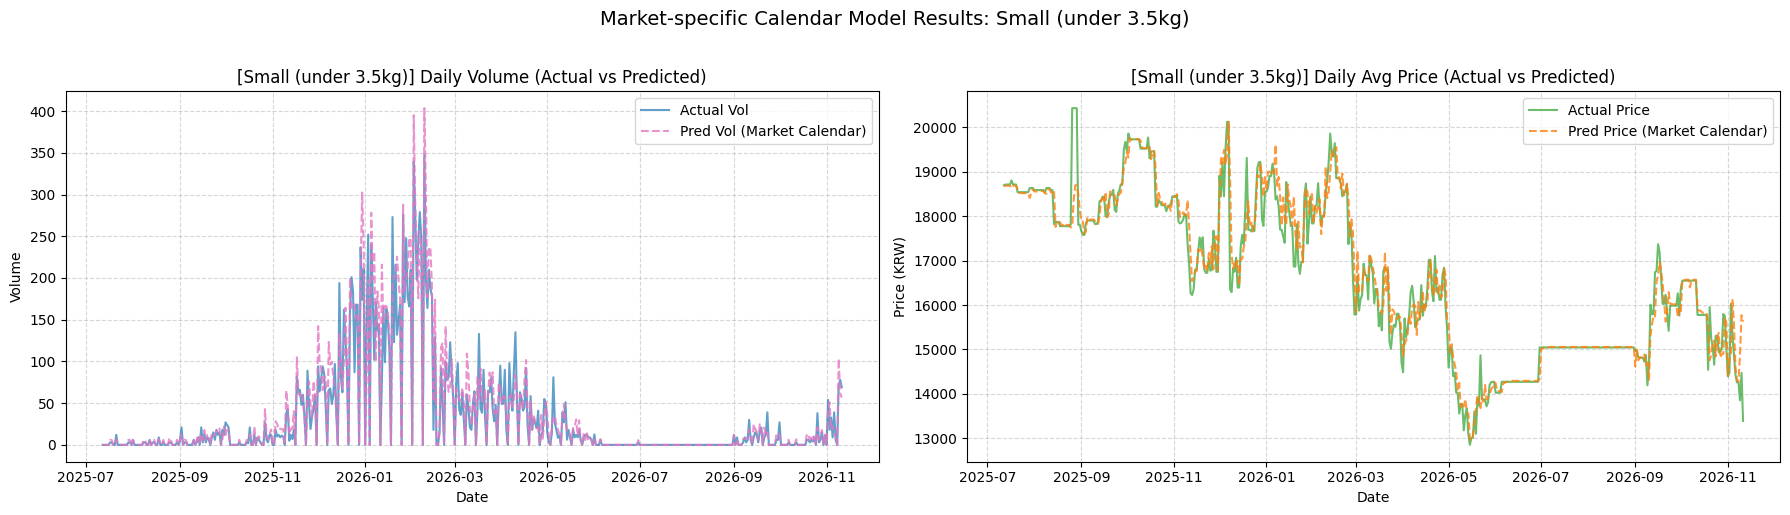

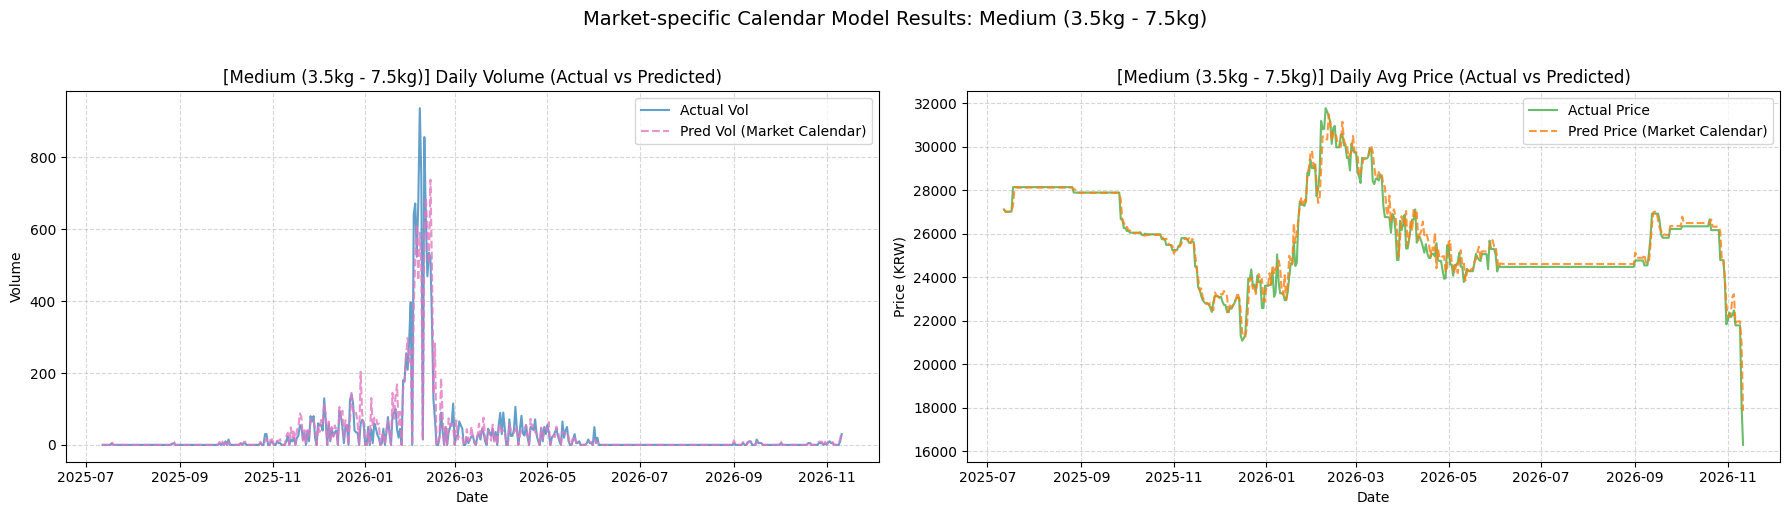

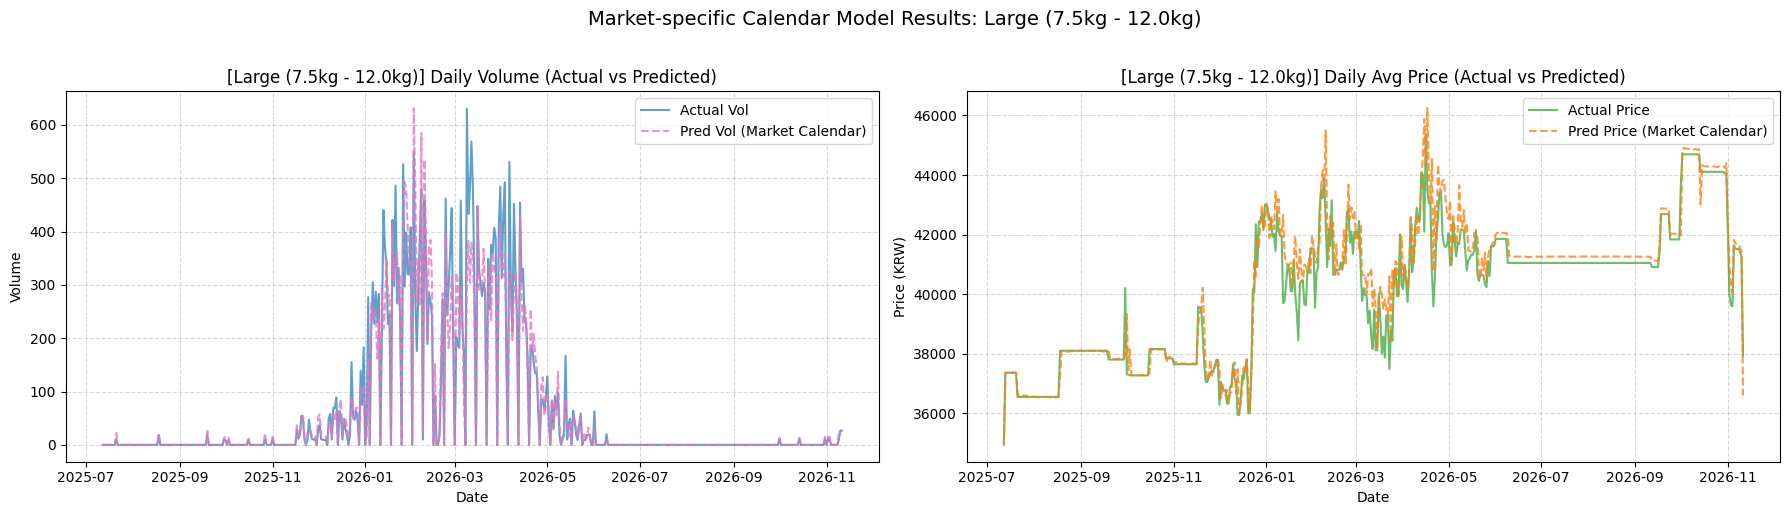

In [39]:
import matplotlib.pyplot as plt

# Ensure safe font settings to prevent unicode block errors
plt.rc('font', family='sans-serif')
plt.rcParams['axes.unicode_minus'] = False

# Map Korean group names to safe English labels for plotting
group_label_map = {
    '소형(3.5kg이하)': 'Small (under 3.5kg)',
    '중형(3.5kg초과~7.5kg이하)': 'Medium (3.5kg - 7.5kg)',
    '대형(7.5kg초과~12kg이하)': 'Large (7.5kg - 12.0kg)'
}

active_groups = ['소형(3.5kg이하)', '중형(3.5kg초과~7.5kg이하)', '대형(7.5kg초과~12kg이하)']

for target_group in active_groups:
    if target_group in group_results_by_market_calendar:
        plot_data = group_results_by_market_calendar[target_group]['data']
        eng_group_label = group_label_map.get(target_group, target_group)

        # Aggregate by date to see total trends
        daily_plot = plot_data.groupby('trd_clcln_ymd').agg({
            '총거래량': 'sum',
            'predicted_volume': 'sum',
            '평균가격': 'mean',
            'predicted_price': 'mean'
        }).reset_index()

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))

        # 1. Volume Plot (Actual vs Predicted)
        ax1.plot(daily_plot['trd_clcln_ymd'], daily_plot['총거래량'], label='Actual Vol', color='#1f77b4', alpha=0.7)
        ax1.plot(daily_plot['trd_clcln_ymd'], daily_plot['predicted_volume'], label='Pred Vol (Market Calendar)', color='#e377c2', alpha=0.8, linestyle='--')
        ax1.set_title(f'[{eng_group_label}] Daily Volume (Actual vs Predicted)', fontsize=12)
        ax1.set_xlabel('Date')
        ax1.set_ylabel('Volume')
        ax1.legend()
        ax1.grid(True, linestyle='--', alpha=0.5)

        # 2. Price Plot (Actual vs Predicted)
        ax2.plot(daily_plot['trd_clcln_ymd'], daily_plot['평균가격'], label='Actual Price', color='#2ca02c', alpha=0.7)
        ax2.plot(daily_plot['trd_clcln_ymd'], daily_plot['predicted_price'], label='Pred Price (Market Calendar)', color='#ff7f0e', alpha=0.8, linestyle='--')
        ax2.set_title(f'[{eng_group_label}] Daily Avg Price (Actual vs Predicted)', fontsize=12)
        ax2.set_xlabel('Date')
        ax2.set_ylabel('Price (KRW)')
        ax2.legend()
        ax2.grid(True, linestyle='--', alpha=0.5)

        plt.suptitle(f'Market-specific Calendar Model Results: {eng_group_label}', fontsize=14, y=1.02)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Results for group '{target_group}' not found.")